<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter4/pinn_1_hidden_layer_jax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



Nonlinear Pendulum (25s): JAX 1-Layer PINN vs Exact vs Linear


Starting training with JAX + SciPy L-BFGS-B...
Notice how fast the iterations fly by now!


/tmp/ipykernel_1024/2999868930.py:114: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


JAX 1-Layer | Iteration   50 | Loss: 0.067441
JAX 1-Layer | Iteration  100 | Loss: 0.048811
JAX 1-Layer | Iteration  150 | Loss: 0.007355
JAX 1-Layer | Iteration  200 | Loss: 0.006320
JAX 1-Layer | Iteration  250 | Loss: 0.006064
JAX 1-Layer | Iteration  300 | Loss: 0.005158
JAX 1-Layer | Iteration  350 | Loss: 0.004786
JAX 1-Layer | Iteration  400 | Loss: 0.004616
JAX 1-Layer | Iteration  450 | Loss: 0.004575
JAX 1-Layer | Iteration  500 | Loss: 0.004458
JAX 1-Layer | Iteration  550 | Loss: 0.004350
JAX 1-Layer | Iteration  600 | Loss: 0.004017
JAX 1-Layer | Iteration  650 | Loss: 0.003828
JAX 1-Layer | Iteration  700 | Loss: 0.003781
JAX 1-Layer | Iteration  750 | Loss: 0.003680
JAX 1-Layer | Iteration  800 | Loss: 0.003638
JAX 1-Layer | Iteration  850 | Loss: 0.003551
JAX 1-Layer | Iteration  900 | Loss: 0.003496
JAX 1-Layer | Iteration  950 | Loss: 0.003442
JAX 1-Layer | Iteration 1000 | Loss: 0.003420

Training Complete! Final Loss: 0.003419


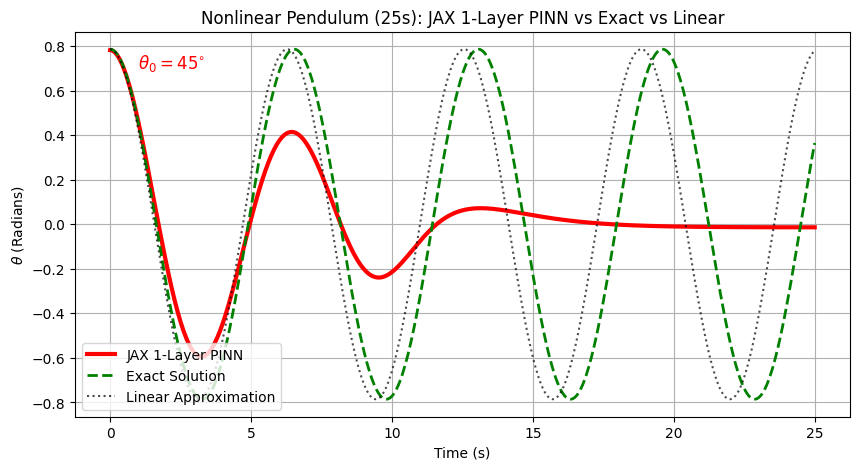

In [1]:
import jax
import jax.numpy as jnp
from jax import jit, value_and_grad

# CRITICAL: SciPy's optimizer uses 64-bit precision floats.
# JAX defaults to 32-bit. We must force JAX to use 64-bit to prevent crashes!
jax.config.update("jax_enable_x64", True)

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import scipy.special as sp

def unpack_weights(params, H):
    """Reconstructs the weight matrices from the flat 1D array."""
    idx = 0
    W1 = params[idx : idx+H].reshape(1, H); idx += H
    b1 = params[idx : idx+H].reshape(1, H); idx += H
    W2 = params[idx : idx+H].reshape(H, 1); idx += H
    b2 = params[idx : idx+1].reshape(1, 1)
    return W1, b1, W2, b2

def pack_weights(W1, b1, W2, b2):
    """Flattens weights into a 1D array."""
    return np.concatenate([W1.flatten(), b1.flatten(), W2.flatten(), b2.flatten()])

def forward_with_physics(params, t, H):
    """
    Calculates position, velocity, and acceleration analytically.
    (This is identical to our Pure NumPy math, just using jnp instead of np!)
    """
    W1, b1, W2, b2 = unpack_weights(params, H)

    # --- TIME SCALING ---
    t_max = 25.0
    tau = t / t_max
    dtau_dt = 1.0 / t_max

    # 1. Feed-Forward
    z = jnp.dot(tau, W1) + b1
    a = jnp.tanh(z)
    theta = jnp.dot(a, W2) + b2

    # 2. First Derivative (Velocity)
    da_dt = (1 - a**2) * W1
    velocity = jnp.dot(da_dt, W2) * dtau_dt

    # 3. Second Derivative (Acceleration)
    d2a_dt2 = -2 * a * (1 - a**2) * (W1**2)
    acceleration = jnp.dot(d2a_dt2, W2) * (dtau_dt**2)

    return theta, velocity, acceleration

# Define the function normally first
def compute_loss(params, t_domain, t_ic, theta_0, omega_0, H):
    """Calculates the total error."""
    # Physics Loss
    theta, _, acceleration = forward_with_physics(params, t_domain, H)
    residual = acceleration + jnp.sin(theta)
    loss_ode = jnp.mean(residual**2)

    # Initial Condition Loss
    theta_pred_ic, velocity_pred_ic, _ = forward_with_physics(params, t_ic, H)
    loss_ic_position = jnp.mean((theta_pred_ic - theta_0)**2)
    loss_ic_velocity = jnp.mean((velocity_pred_ic - omega_0)**2)

    return loss_ode + loss_ic_position + loss_ic_velocity

# Now explicitly wrap it in JIT, passing the function as the first argument
compute_loss = jit(compute_loss, static_argnums=(5,))

# THE MAGIC: jax.value_and_grad generates the exact backpropagation calculus instantly.
# It returns a function that outputs both the Loss AND the Gradients at the exact same time.
# We must also tell the JIT compiler here that 'H' is static!
loss_and_grad = jit(value_and_grad(compute_loss), static_argnums=(5,))

def scipy_objective(params, t_domain, t_ic, theta_0, omega_0, H):
    """A wrapper to feed JAX results back into SciPy's format."""
    loss, grads = loss_and_grad(params, t_domain, t_ic, theta_0, omega_0, H)
    # Convert JAX arrays back into standard Python/NumPy types for SciPy
    return float(loss), np.array(grads)

# ==========================================
# Training Setup (25 Seconds)
# ==========================================

H = 32  # Number of hidden neurons
t_domain = jnp.linspace(0, 25, 500).reshape(-1, 1)
t_ic = jnp.array([[0.0]])
theta_0 = jnp.pi / 4
omega_0 = 0.0

# Initialize Random Weights
np.random.seed(42) # Seed for reproducibility
W1 = np.random.randn(1, H) * np.sqrt(2.0 / (1 + H))
b1 = np.zeros((1, H))
W2 = np.random.randn(H, 1) * np.sqrt(2.0 / (H + 1))
b2 = np.zeros((1, 1))
initial_weights = pack_weights(W1, b1, W2, b2)

# --- Callback for Progress Tracking ---
progress = {'iterations': 0}

def monitor_progress(xk):
    progress['iterations'] += 1
    if progress['iterations'] % 50 == 0:
        # We can quickly calculate the loss to print it out
        current_loss = compute_loss(xk, t_domain, t_ic, theta_0, omega_0, H)
        print(f"JAX 1-Layer | Iteration {progress['iterations']:4d} | Loss: {float(current_loss):.6f}")

print("Starting training with JAX + SciPy L-BFGS-B...")
print("Notice how fast the iterations fly by now!")

res = minimize(
    fun=scipy_objective,
    x0=initial_weights,
    args=(t_domain, t_ic, theta_0, omega_0, H),
    method='L-BFGS-B',
    jac=True, # CRITICAL CHANGE: We tell SciPy "True, we are providing the exact gradients!"
    callback=monitor_progress,
    options={'maxiter': 5000, 'maxfun': 100000, 'disp': False}
)

final_weights = res.x
print(f"\nTraining Complete! Final Loss: {res.fun:.6f}")

# ==========================================
# Evaluation and Plotting
# ==========================================

theta_predicted, _, _ = forward_with_physics(final_weights, t_domain, H)

# Convert JAX array back to NumPy for plotting
t_plot = np.array(t_domain).flatten()
theta_plot = np.array(theta_predicted).flatten()

# Exact Solution
k = np.sin(theta_0 / 2)
m = k**2
sn, cn, dn, ph = sp.ellipj(t_plot, m)
exact_solution = 2 * np.arcsin(k * (cn / dn))

# Linear Solution (Small Angle Approximation)
linear_solution = theta_0 * np.cos(t_plot)

plt.figure(figsize=(10, 5))
plt.plot(t_plot, theta_plot, 'r-', linewidth=3, label='JAX 1-Layer PINN')
plt.plot(t_plot, exact_solution, 'g--', linewidth=2, label='Exact Solution')
plt.plot(t_plot, linear_solution, 'k:', alpha=0.7, label='Linear Approximation')

plt.title("Nonlinear Pendulum (25s): JAX 1-Layer PINN vs Exact vs Linear")
plt.text(1, 0.7, "$\\theta_{0}=45^{\\circ}$", fontsize=12, color='red')
plt.xlabel("Time (s)")
plt.ylabel("$\\theta$ (Radians)")
plt.legend(loc='lower left')
plt.grid(True)
plt.show()